# Income Fluctuations: Four-Period Framework

## 1. Dates, states, and histories

There are four dates, $t=0,1,2,3$. At $t=0$ the endowment is known. At each subsequent date, a high ($H$) or low ($L$) state occurs with probabilities $\pi_H$ and $\pi_L=1-\pi_H$. For now, state realizations are independent across dates.

A node is identified by the **history** of states realized up to that date. The empty history $\varnothing$ represents today.

- $t=0$: $\varnothing$ (1 node)
- $t=1$: $H,L$ (2 nodes)
- $t=2$: $HH,HL,LH,LL$ (4 nodes)
- $t=3$: $HHH,HHL,HLH,HLL,LHH,LHL,LLH,LLL$ (8 nodes)

Thus there are $1+2+4+8=15$ nodes and **eight complete future histories**. Each node has its own endowment $e_h$. The discount factor is $\beta$; we will specify preferences and optimization later.


## 2. Parameters and state tree

Change the probabilities and discount factor below as needed.


In [1]:
from itertools import product

beta = 0.95
pi_H = 0.5
pi_L = 1 - pi_H
assert 0 <= pi_H <= 1 and abs(pi_H + pi_L - 1) < 1e-12

nodes_by_date = {0: ['']}
for t in range(1, 4):
    nodes_by_date[t] = [''.join(s) for s in product('HL', repeat=t)]

for t, histories in nodes_by_date.items():
    print(f"t={t}: {', '.join(h or 'today' for h in histories)}")
print('Total nodes:', sum(map(len, nodes_by_date.values())))


t=0: today
t=1: H, L
t=2: HH, HL, LH, LL
t=3: HHH, HHL, HLH, HLL, LHH, LHL, LLH, LLL
Total nodes: 15


## 3. Endowments: deterministic path and high-state growth

Start with four baseline endowments, one for each date: $\bar e_0,\bar e_1,\bar e_2,\bar e_3$. When $g_H=1$, endowments fluctuate **only across time** and are the same at every node of a given date.

To introduce uncertainty, multiply the baseline endowment by $g_H$ once for every high state realized along the history $h$:

$$e_t(h)=\bar e_t\,g_H^{N_H(h)},$$

where $N_H(h)$ counts the number of $H$ realizations in $h$. For example, $e_3(HHL)=\bar e_3g_H^2$ and $e_3(LLL)=\bar e_3$. The 15 node-specific endowments are constructed automatically below.


In [2]:
# Enter the four baseline endowments (time variation only).
e_time = [10.0, 11.0, 12.0, 13.0]

# Set to 1.0 for no uncertainty; values above 1 add growth after each H.
g_H = 1.50

assert len(e_time) == 4 and all(e > 0 for e in e_time)
assert g_H > 0

endowment = {
    h: e_time[t] * g_H**h.count('H')
    for t, histories in nodes_by_date.items()
    for h in histories
}

for t, histories in nodes_by_date.items():
    print(f"Period {t}:")
    for h in histories:
        print(f"  {h or 'today':>5}: {endowment[h]:.3f}")


Period 0:
  today: 10.000
Period 1:
      H: 16.500
      L: 11.000
Period 2:
     HH: 27.000
     HL: 18.000
     LH: 18.000
     LL: 12.000
Period 3:
    HHH: 43.875
    HHL: 29.250
    HLH: 29.250
    HLL: 19.500
    LHH: 29.250
    LHL: 19.500
    LLH: 19.500
    LLL: 13.000


## 4. Probabilities of histories

With independent realizations, a history $h$ has probability $\Pr(h)=\pi_H^{N_H(h)}\pi_L^{N_L(h)}$. The probabilities of all nodes **at a given date** sum to one.


In [3]:
def probability(history):
    return pi_H**history.count('H') * pi_L**history.count('L')

for t, histories in nodes_by_date.items():
    print(f"t={t}: " + ', '.join(f"{h or 'today'}: {probability(h):.4f}" for h in histories))
    assert abs(sum(probability(h) for h in histories) - 1) < 1e-12


t=0: today: 1.0000
t=1: H: 0.5000, L: 0.5000
t=2: HH: 0.2500, HL: 0.2500, LH: 0.2500, LL: 0.2500
t=3: HHH: 0.1250, HHL: 0.1250, HLH: 0.1250, HLL: 0.1250, LHH: 0.1250, LHL: 0.1250, LLH: 0.1250, LLL: 0.1250


## 5. Felicity and lifetime expected utility

The **felicity function** is CRRA with coefficient of relative risk aversion $\gamma>0$:

$$u(c)=\begin{cases}\dfrac{c^{1-\gamma}-1}{1-\gamma}, & \gamma\ne 1,\\[6pt]\log c, & \gamma=1.\end{cases}$$

Consumption must be positive. The subtraction of 1 is a normalization and does not affect choices. With discount factor $\beta$, expected lifetime utility for a consumption plan $\{c_h\}$ on the tree is

$$U=\sum_{t=0}^3\beta^t\sum_{h\in\{H,L\}^t}\Pr(h)u(c_h).$$

This specifies preferences only; we will add budget constraints and solve for consumption later.


In [4]:
import math

gamma = 2.0  # coefficient of relative risk aversion

def felicity(c, gamma=gamma):
    if c <= 0:
        raise ValueError("Consumption must be positive")
    if gamma <= 0:
        raise ValueError("gamma must be positive")
    if gamma == 1:
        return math.log(c)
    return (c**(1 - gamma) - 1) / (1 - gamma)

# Example: evaluate felicity at a single consumption level
print("u(10) =", felicity(10))


u(10) = 0.9


## 6. Exogenous prices of the 14 Arrow–Debreu securities

A security indexed by a future history $h$ delivers **one unit of consumption at that node only**. There are $2+4+8=14$ such securities, all traded at date 0. We take their prices as given:

$$q_t(h)=\frac{\Pr(h)}{R^t},\qquad R=1+r.$$

**Crucial distinction:** these are **exogenous, actuarially fair state prices**. They depend on the market gross interest rate $R$ and the state probabilities, **not on this household's preference parameters** $\beta$ or $\gamma$. Changing $\beta$ or $\gamma$ changes optimal consumption and asset demands, but **not** the prices in this partial-equilibrium exercise. In general equilibrium, market-clearing prices could depend on preferences.

At every date $t$, the state prices add up to the price of a risk-free zero-coupon bond: $\sum_{|h|=t}q_t(h)=R^{-t}$.


In [5]:
# Exogenous market interest rate: independent of beta and gamma
r = 0.04
R = 1 + r
assert R > 0 and 0 < pi_H < 1

prices = {
    h: probability(h) / R**t
    for t in range(1, 4)
    for h in nodes_by_date[t]
}

for t in range(1, 4):
    print(f"Date {t}:")
    for h in nodes_by_date[t]:
        print(f"  {h:3s}: q = {prices[h]:.6f}")
    assert abs(sum(prices[h] for h in nodes_by_date[t]) - R**(-t)) < 1e-12


Date 1:
  H  : q = 0.480769
  L  : q = 0.480769
Date 2:
  HH : q = 0.231139
  HL : q = 0.231139
  LH : q = 0.231139
  LL : q = 0.231139
Date 3:
  HHH: q = 0.111125
  HHL: q = 0.111125
  HLH: q = 0.111125
  HLL: q = 0.111125
  LHH: q = 0.111125
  LHL: q = 0.111125
  LLH: q = 0.111125
  LLL: q = 0.111125


## 7. Household problem and optimal consumption

The household maximizes discounted expected CRRA felicity subject to the present-value budget constraint:

$$\max_{\{c_t(h)>0\}}\sum_{t=0}^3\beta^t\sum_{|h|=t}\Pr(h)u(c_t(h)),$$

$$c_0+\sum_{t=1}^3\sum_{|h|=t}q_t(h)c_t(h)
=e_0+\sum_{t=1}^3\sum_{|h|=t}q_t(h)e_t(h).$$

The first-order conditions are $\beta^t\Pr(h)c_t(h)^{-\gamma}=\lambda q_t(h)$, including $c_0^{-\gamma}=\lambda$. Under the assumed prices, probabilities cancel:

$$\boxed{c_t(h)=c_0(\beta R)^{t/\gamma}}.$$

Thus consumption is **fully insured across states at each date**, although it may change across dates. Define total present-value wealth $W$ and $k=(\beta R)^{1/\gamma}$. Then

$$W=e_0+\sum_{t=1}^3\sum_{|h|=t}q_t(h)e_t(h),\qquad
c_0=\frac{W}{\sum_{t=0}^3(k/R)^t}.$$


## 8. Why complete markets imply full insurance: a proof

**Proposition.** Suppose every future history has positive probability, the household can buy or sell all 14 Arrow–Debreu securities, and their date-0 prices are

$$
q_t(h)=\frac{\Pr(h)}{R^t}.
$$

If the household has CRRA felicity with $\gamma>0$, optimal consumption is **the same at every node of a given date**. In particular, consumption does not depend on the realized income history.

**Proof.** The household chooses $c_0$ and $c_t(h)$ to maximize

$$
u(c_0)+\sum_{t=1}^3\beta^t\sum_{h\in\{H,L\}^t}
\Pr(h)u(c_t(h))
$$

subject to the single present-value budget constraint

$$
c_0+\sum_{t=1}^3\sum_h q_t(h)c_t(h)
=
e_0+\sum_{t=1}^3\sum_h q_t(h)e_t(h).
$$

Let $\lambda$ be the multiplier on this constraint. At an interior optimum, the first-order condition for consumption at any future node $(t,h)$ is

$$
\beta^t\Pr(h)u'(c_t(h))=\lambda q_t(h).
$$

For CRRA felicity, $u'(c)=c^{-\gamma}$. Substituting the exogenous Arrow–Debreu price gives

$$
\beta^t\Pr(h)c_t(h)^{-\gamma}
=\lambda\frac{\Pr(h)}{R^t}.
$$

Since $\Pr(h)>0$, **the history probability cancels**:

$$
c_t(h)^{-\gamma}=\frac{\lambda}{(\beta R)^t}.
$$

The right-hand side depends on the date $t$ but **not** on the history $h$. Therefore,

$$
\boxed{c_t(h)=\left(\frac{(\beta R)^t}{\lambda}\right)^{1/\gamma}
\quad\text{for every history }h\text{ at date }t.}
$$

The date-0 first-order condition is $u'(c_0)=\lambda$, or $\lambda=c_0^{-\gamma}$. Hence

$$
\boxed{c_t(h)=c_0(\beta R)^{t/\gamma}.}
$$

Thus consumption may change **across dates**, but is identical **across states at each date**: the household is fully insured against its idiosyncratic endowment fluctuations. $\square$

**Economic interpretation.** Endowments can differ substantially across histories, but the household uses its 14 Arrow–Debreu securities to transfer resources from high-endowment nodes to low-endowment nodes. Full insurance here relies on *complete markets and actuarially fair state prices*. It does not hold in general for arbitrary state prices. The prices are imposed externally and do **not** depend on the household's $\beta$ or $\gamma$.


In [6]:
# Solve analytically for consumption at all 15 nodes
assert 0 < beta and gamma > 0
wealth = endowment[''] + sum(prices[h] * endowment[h] for h in prices)
k = (beta * R)**(1 / gamma)
c0 = wealth / sum((k / R)**t for t in range(4))
consumption = {
    h: c0 * k**t
    for t, histories in nodes_by_date.items()
    for h in histories
}

print(f"Present-value wealth: {wealth:.6f}")
for t, histories in nodes_by_date.items():
    print(f"t={t}: optimal consumption = {consumption[histories[0]]:.6f}")

spending = consumption[''] + sum(prices[h] * consumption[h] for h in prices)
assert abs(spending - wealth) < 1e-9


Present-value wealth: 63.128756
t=0: optimal consumption = 16.869171
t=1: optimal consumption = 16.767651
t=2: optimal consumption = 16.666741
t=3: optimal consumption = 16.566439


### Graphical presentation: consumption and endowments

The first graph compares **optimal consumption** with the endowments at all 15 nodes, grouped by date. Each history is labeled. The second graph displays the **full-insurance consumption path**: all histories at a given date have identical consumption, even though endowments vary by state. Both figures update when the parameters above change.


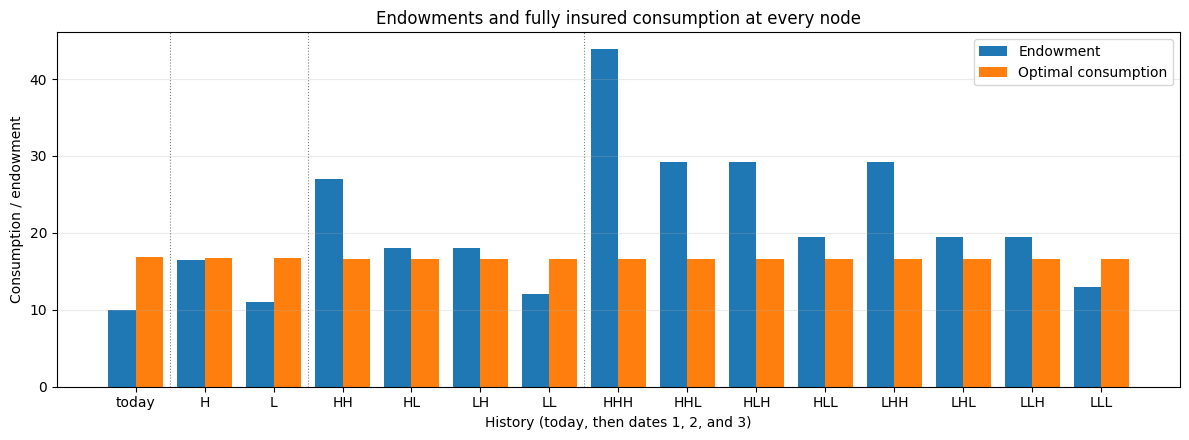

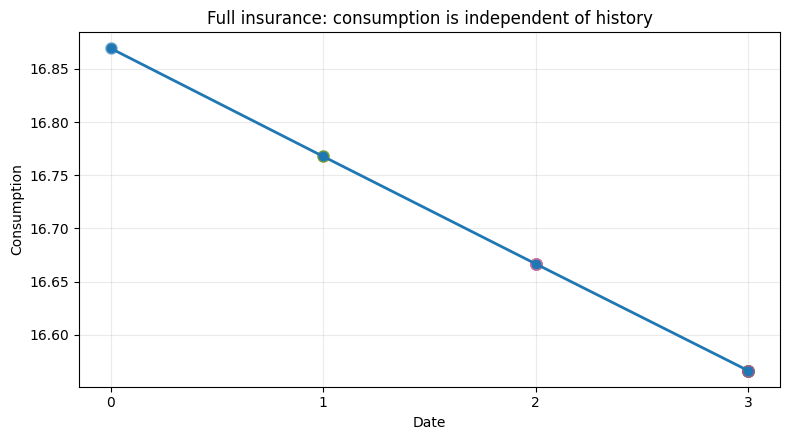

In [7]:
import matplotlib.pyplot as plt

all_histories = [h for t in range(4) for h in nodes_by_date[t]]
labels = [h or 'today' for h in all_histories]
positions = list(range(len(all_histories)))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar([x - 0.2 for x in positions], [endowment[h] for h in all_histories],
       width=0.4, label='Endowment')
ax.bar([x + 0.2 for x in positions], [consumption[h] for h in all_histories],
       width=0.4, label='Optimal consumption')
ax.set_xticks(positions, labels)
ax.set_xlabel('History (today, then dates 1, 2, and 3)')
ax.set_ylabel('Consumption / endowment')
ax.set_title('Endowments and fully insured consumption at every node')
ax.legend()
ax.grid(axis='y', alpha=0.25)
for boundary in [0.5, 2.5, 6.5]:
    ax.axvline(boundary, color='gray', linewidth=0.8, linestyle=':')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for h in all_histories:
    t = len(h)
    ax.scatter(t, consumption[h], alpha=0.55, s=65)
ax.plot(range(4), [consumption[nodes_by_date[t][0]] for t in range(4)],
        marker='o', linewidth=2, label='Optimal consumption')
ax.set_xticks(range(4))
ax.set_xlabel('Date')
ax.set_ylabel('Consumption')
ax.set_title('Full insurance: consumption is independent of history')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 9. Net demands for the 14 Arrow–Debreu securities

With all contingent claims traded today, the net holding of the security paying at node $h$ is

$$\boxed{a(h)=c_t(h)-e_t(h),\qquad |h|=t\ge 1.}$$

A **positive** holding buys future consumption at that node; a **negative** holding sells part of the endowment there. The initial cost of the portfolio is $\sum_h q(h)a(h)=e_0-c_0$. Thus the household finances its date-0 consumption choice and insures all future consumption through the portfolio. **These are date-0 Arrow–Debreu positions**, not quantities traded again at future nodes.


In [8]:
# Compute and display each Arrow–Debreu security demand
asset_demand = {h: consumption[h] - endowment[h] for h in prices}

print(f"{'History':8s} {'Endowment':>11s} {'Consumption':>12s} {'Price':>10s} {'Net demand':>12s}")
for t in range(1, 4):
    for h in nodes_by_date[t]:
        print(f"{h:8s} {endowment[h]:11.4f} {consumption[h]:12.4f} "
              f"{prices[h]:10.6f} {asset_demand[h]:12.4f}")

portfolio_cost = sum(prices[h] * asset_demand[h] for h in prices)
print(f"\nCost of net Arrow portfolio: {portfolio_cost:.6f}")
print(f"Date-0 saving (e0 - c0): {endowment[''] - consumption['']:.6f}")
assert abs(portfolio_cost - (endowment[''] - consumption[''])) < 1e-9


History    Endowment  Consumption      Price   Net demand
H            16.5000      16.7677   0.480769       0.2677
L            11.0000      16.7677   0.480769       5.7677
HH           27.0000      16.6667   0.231139     -10.3333
HL           18.0000      16.6667   0.231139      -1.3333
LH           18.0000      16.6667   0.231139      -1.3333
LL           12.0000      16.6667   0.231139       4.6667
HHH          43.8750      16.5664   0.111125     -27.3086
HHL          29.2500      16.5664   0.111125     -12.6836
HLH          29.2500      16.5664   0.111125     -12.6836
HLL          19.5000      16.5664   0.111125      -2.9336
LHH          29.2500      16.5664   0.111125     -12.6836
LHL          19.5000      16.5664   0.111125      -2.9336
LLH          19.5000      16.5664   0.111125      -2.9336
LLL          13.0000      16.5664   0.111125       3.5664

Cost of net Arrow portfolio: -6.869171
Date-0 saving (e0 - c0): -6.869171


### Graphical presentation: Arrow–Debreu asset demands

Each bar shows the **net units** of the Arrow security bought (positive) or sold (negative) at date 0. The second panel shows the **date-0 market value** of each position, $q_t(h)a_t(h)$; these values sum to date-0 saving $e_0-c_0$.


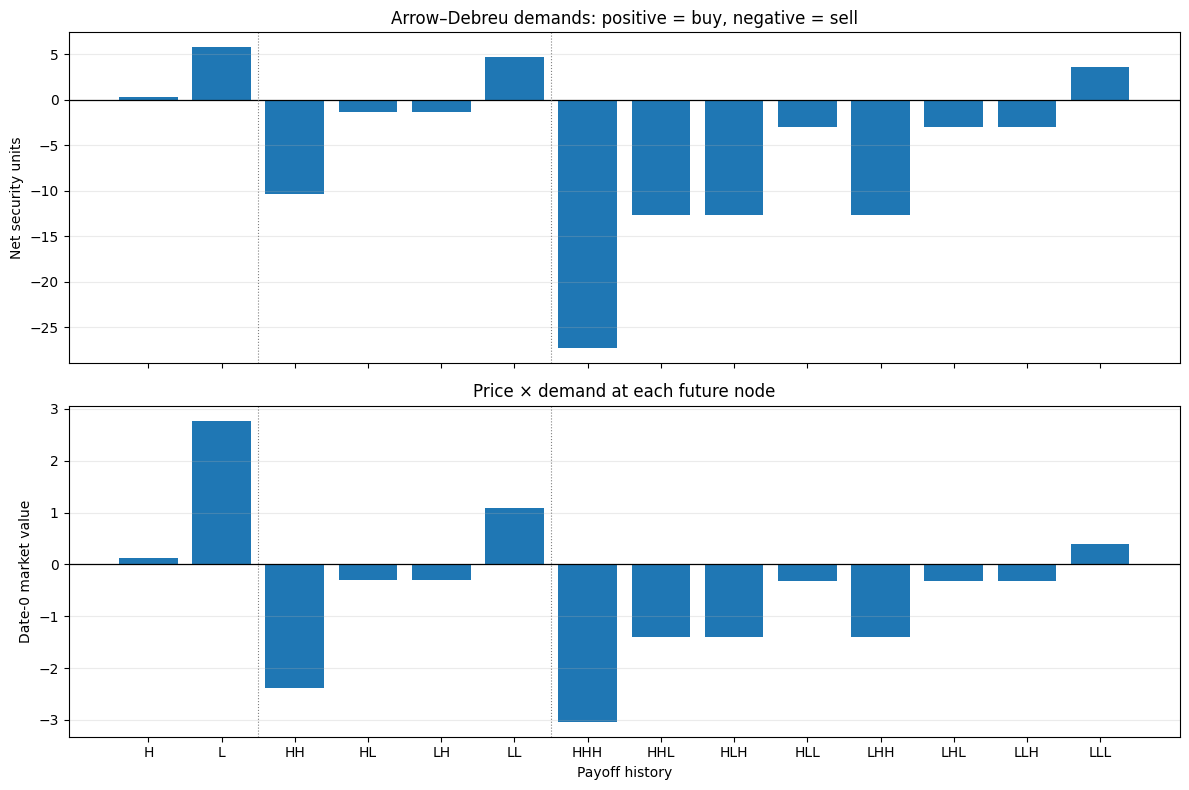

Total value of Arrow positions: -6.869171
Date-0 saving: -6.869171


In [9]:
future_histories = [h for t in range(1, 4) for h in nodes_by_date[t]]
units = [asset_demand[h] for h in future_histories]
values = [prices[h] * asset_demand[h] for h in future_histories]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].bar(future_histories, units)
axes[0].axhline(0, color='black', linewidth=0.9)
axes[0].set_ylabel('Net security units')
axes[0].set_title('Arrow–Debreu demands: positive = buy, negative = sell')
axes[0].grid(axis='y', alpha=0.25)

axes[1].bar(future_histories, values)
axes[1].axhline(0, color='black', linewidth=0.9)
axes[1].set_ylabel('Date-0 market value')
axes[1].set_xlabel('Payoff history')
axes[1].set_title('Price × demand at each future node')
axes[1].grid(axis='y', alpha=0.25)
for ax in axes:
    for boundary in [1.5, 5.5]:
        ax.axvline(boundary, color='gray', linewidth=0.8, linestyle=':')
plt.tight_layout()
plt.show()
print(f'Total value of Arrow positions: {sum(values):.6f}')
print(f'Date-0 saving: {endowment[""] - consumption[""]:.6f}')



## 10. Two additional canonical market structures

We now compare **three** cases using exactly the same endowments, probabilities, preferences, and market interest rate:

1. **No assets (autarky):** the household cannot transfer resources across dates or states. Therefore $c_t(h)=e_t(h)$.
2. **Only three bonds:** at date 0 the household can trade three *risk-free zero-coupon bonds*, one paying one unit at each future date $t=1,2,3$, **regardless of the history**. Their date-0 prices are $1/R$, $1/R^2$, and $1/R^3$. Denote their date-0 net holdings by $b_1,b_2,b_3$. There are **no contingent securities** and, in this benchmark, no additional trades after date 0.
3. **Complete markets:** the 14 Arrow–Debreu securities studied above.

For the three-bond economy, consumption is

$$
c_0=e_0-\sum_{t=1}^3\frac{b_t}{R^t},\qquad
c_t(h)=e_t(h)+b_t.
$$

Thus bonds allow transfers **between dates**, but cannot directly insure differences **across histories at the same date**. Bond positions may be negative (borrowing), provided consumption remains strictly positive at every node.

The household chooses $(b_1,b_2,b_3)$ to maximize expected lifetime felicity. The interior first-order conditions are

$$
\boxed{\beta^t R^t\,\mathbb E[u'(e_t(h)+b_t)]=u'(c_0),\qquad t=1,2,3.}
$$

Unlike the complete-markets case, the expectation of marginal felicity generally depends on income risk. **All security prices remain exogenous and independent of $\beta$ and $\gamma$.**


The three-bond case below is now solved by the **general payoff-matrix optimizer** introduced in the code cell. Each security is a dictionary of future-node payoffs, and its date-0 price is calculated from exogenous Arrow–Debreu prices. The same solver can handle any independent collection of date-0 traded securities.


When the specified securities span all 14 future-node payoffs, the solver uses the analytical complete-markets allocation and computes the replicating portfolio by linear algebra. This avoids numerical optimization error in the full-rank benchmark.

In [10]:
# General date-0 securities: columns of a future-node payoff matrix
import numpy as np
from scipy.optimize import minimize

future_histories = [h for t in range(1, 4) for h in nodes_by_date[t]]
consumption_no_assets = dict(endowment)
floor = 1e-8

def expected_utility(c):
    return sum(beta**t * sum(probability(h) * felicity(c[h])
                            for h in nodes_by_date[t]) for t in range(4))

def make_payoff_matrix(securities):
    """securities: {name: {future_history: payoff}}, zero if omitted."""
    unknown = set().union(*(set(s) for s in securities.values())) - set(future_histories) if securities else set()
    if unknown:
        raise ValueError(f'Unknown future histories: {sorted(unknown)}')
    names = list(securities)
    A = np.array([[securities[name].get(h, 0.0) for name in names]
                  for h in future_histories], dtype=float).reshape(len(future_histories), len(names))
    if not np.all(np.isfinite(A)):
        raise ValueError('Payoffs must be finite.')
    q_AD = np.array([prices[h] for h in future_histories])
    return names, A, q_AD @ A

def solve_securities(securities):
    """Optimize date-0 holdings subject to positive consumption at all nodes."""
    names, A, q = make_payoff_matrix(securities)
    rank = np.linalg.matrix_rank(A) if len(names) else 0
    if len(names) == 0:
        return {'names': names, 'payoffs': A, 'prices': q,
                'holdings': np.array([]), 'rank': rank,
                'consumption': dict(endowment), 'utility': expected_utility(endowment)}
    # Independent payoff columns ensure unique portfolio holdings.
    if rank < len(names):
        raise ValueError('Redundant securities: remove linearly dependent payoff columns.')
    # If the payoff columns span every future node, use the exact
    # complete-markets consumption formula rather than a numerical optimizer.
    # This avoids small SLSQP errors that can fail node-by-node assertions.
    if rank == len(future_histories):
        target = np.array([consumption[h] - endowment[h]
                           for h in future_histories])
        holdings = np.linalg.solve(A, target)
        c = dict(consumption)
        assert np.allclose(A @ holdings, target, atol=1e-9)
        assert abs(c[''] - (endowment[''] - q @ holdings)) < 1e-8
        return {'names': names, 'payoffs': A, 'prices': q,
                'holdings': holdings, 'rank': rank,
                'consumption': c, 'utility': expected_utility(c)}
    e_future = np.array([endowment[h] for h in future_histories])
    date = np.array([len(h) for h in future_histories])
    weights = np.array([beta**len(h) * probability(h) for h in future_histories])
    def c_array(a):
        return endowment[''] - q @ a, e_future + A @ a
    def objective(a):
        c0, cf = c_array(a)
        if c0 <= 0 or np.any(cf <= 0):
            return 1e15
        if gamma == 1:
            return -(np.log(c0) + weights @ np.log(cf))
        return -((c0**(1-gamma)-1)/(1-gamma)
                 + weights @ ((cf**(1-gamma)-1)/(1-gamma)))
    def gradient(a):
        c0, cf = c_array(a)
        if c0 <= 0 or np.any(cf <= 0):
            return np.zeros(len(names))
        return q * c0**(-gamma) - A.T @ (weights * cf**(-gamma))
    constraints = [{'type':'ineq', 'fun':lambda a: c_array(a)[0]-floor,
                    'jac':lambda a: -q},
                   {'type':'ineq', 'fun':lambda a: c_array(a)[1]-floor,
                    'jac':lambda a: A}]
    result = minimize(objective, np.zeros(len(names)), jac=gradient,
                      constraints=constraints, method='SLSQP',
                      options={'ftol':1e-12, 'maxiter':5000})
    c0, cf = c_array(result.x)
    if min(c0, np.min(cf)) <= 0 or not np.isfinite(objective(result.x)):
        raise RuntimeError('No feasible positive-consumption solution found.')
    # Check the first-order conditions for interior solutions.
    if not result.success and np.max(np.abs(gradient(result.x))) > 1e-5:
        raise RuntimeError(f'Optimization failed: {result.message}')
    c = {'':float(c0), **{h:float(v) for h,v in zip(future_histories,cf)}}
    return {'names':names, 'payoffs':A, 'prices':q,
            'holdings':result.x, 'rank':rank,
            'consumption':c, 'utility':expected_utility(c)}

# Canonical example: one date-0 risk-free zero-coupon bond per maturity.
three_bond_securities = {
    f'Bond {t}': {h:1.0 for h in nodes_by_date[t]}
    for t in (1,2,3)
}
bond_solution = solve_securities(three_bond_securities)
bond_demand = {t:bond_solution['holdings'][t-1] for t in (1,2,3)}
bond_prices = {t:bond_solution['prices'][t-1] for t in (1,2,3)}
consumption_bonds = bond_solution['consumption']
print('Bond demands (units):')
for t in (1,2,3):
    print(f'  maturity t={t}: {bond_demand[t]: .6f}, price = {bond_prices[t]:.6f}')
print(f'Expected utility — no assets:       {expected_utility(consumption_no_assets):.6f}')
print(f'Expected utility — three bonds:     {expected_utility(consumption_bonds):.6f}')
print(f'Expected utility — complete markets:{expected_utility(consumption):.6f}')
assert expected_utility(consumption_no_assets) <= expected_utility(consumption_bonds) + 1e-6
assert expected_utility(consumption_bonds) <= expected_utility(consumption) + 1e-6


Bond demands (units):
  maturity t=1:  1.669994, price = 0.961538
  maturity t=2: -1.777715, price = 0.924556
  maturity t=3: -5.341765, price = 0.888996
Expected utility — no assets:       3.447511
Expected utility — three bonds:     3.466848
Expected utility — complete markets:3.488035


### Graphical comparison: uninsured consumption risk

In autarky, consumption equals the endowment at each history, so all income risk is uninsured. With three **date-0 zero-coupon bonds**, consumption at each date is the endowment plus a history-independent amount: the bonds smooth consumption over time but **do not reduce its within-date risk**. Consequently the risk curves for *No assets* and *Three bonds* coincide exactly. Complete markets eliminate within-date consumption risk.

The first plot displays the three consumption allocations at each node. The second compares **probability-weighted** cross-history standard deviations. To prevent the identical no-assets and three-bond lines from hiding one another, we show them with different markers and line styles and label the common line explicitly.


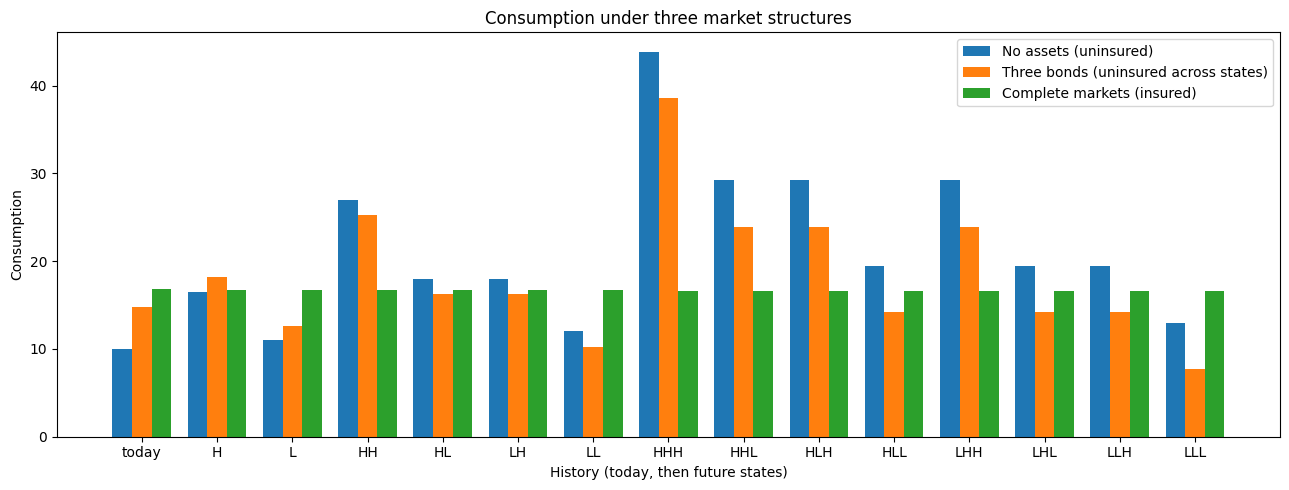

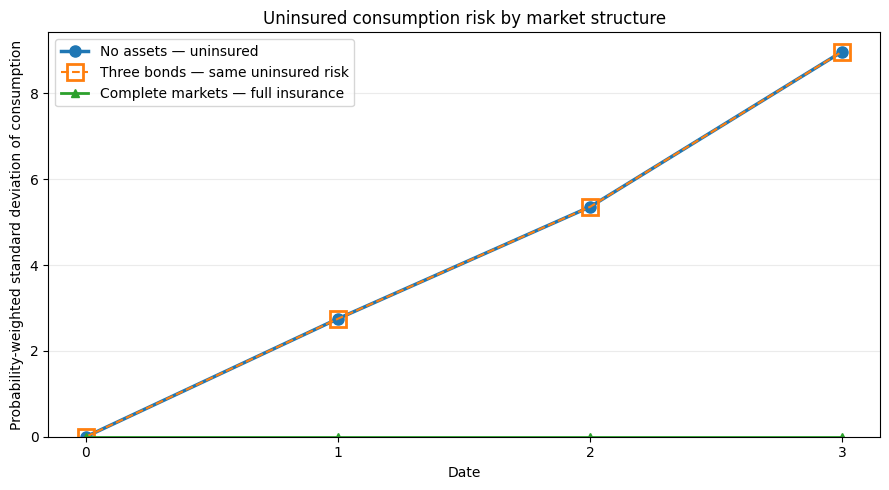

Probability-weighted consumption risk:
Date     No assets     Three bonds     Complete markets
   0       0.00000         0.00000              0.00000
   1       2.75000         2.75000              0.00000
   2       5.35607         5.35607              0.00000
   3       8.97206         8.97206              0.00000


In [11]:
# Compare consumption at all 15 nodes
fig, ax = plt.subplots(figsize=(13, 5))
xx = np.arange(len(all_histories))
w = 0.26
ax.bar(xx-w, [consumption_no_assets[h] for h in all_histories], width=w, label='No assets (uninsured)')
ax.bar(xx, [consumption_bonds[h] for h in all_histories], width=w, label='Three bonds (uninsured across states)')
ax.bar(xx+w, [consumption[h] for h in all_histories], width=w, label='Complete markets (insured)')
ax.set_xticks(xx, labels)
ax.set_xlabel('History (today, then future states)')
ax.set_ylabel('Consumption')
ax.set_title('Consumption under three market structures')
ax.legend()
plt.tight_layout()
plt.show()

# Probability-weighted within-date standard deviation of consumption
def consumption_risk(c, t):
    histories = nodes_by_date[t]
    mean = sum(probability(h) * c[h] for h in histories)
    variance = sum(probability(h) * (c[h] - mean)**2 for h in histories)
    return np.sqrt(max(variance, 0.0))

dates = np.arange(4)
risk_no_assets = [consumption_risk(consumption_no_assets, t) for t in dates]
risk_bonds = [consumption_risk(consumption_bonds, t) for t in dates]
risk_complete = [consumption_risk(consumption, t) for t in dates]

# Risk under the two incomplete-market structures is mathematically identical.
assert np.allclose(risk_no_assets, risk_bonds, atol=1e-9)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(dates, risk_no_assets, '-o', linewidth=2.5,
        markersize=8, label='No assets — uninsured')
# Same curve: hollow squares make the overlap visible.
ax.plot(dates, risk_bonds, '--s', linewidth=1.5,
        markersize=12, markerfacecolor='none', markeredgewidth=2,
        label='Three bonds — same uninsured risk')
ax.plot(dates, risk_complete, '-^', linewidth=2,
        label='Complete markets — full insurance')
ax.set_xticks(dates)
ax.set_xlabel('Date')
ax.set_ylabel('Probability-weighted standard deviation of consumption')
ax.set_title('Uninsured consumption risk by market structure')
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print('Probability-weighted consumption risk:')
print('Date     No assets     Three bonds     Complete markets')
for t in dates:
    print(f'{t:>4}  {risk_no_assets[t]:>12.5f}  {risk_bonds[t]:>14.5f}  {risk_complete[t]:>19.5f}')


### Why no assets and three bonds have the same within-date risk

**No assets:** Consumption equals the endowment at each node: $c_t(h)=e_t(h)$. Therefore $\operatorname{Var}_t(c)=\operatorname{Var}_t(e)$.

**Three bonds traded only at date 0:** The household chooses one non-contingent payment $b_t$ for each maturity $t$. That payment is identical across all histories at that date:

$$c_t(h)=e_t(h)+b_t.$$

Adding the same constant to every realization changes the **mean** but not the **variance**:

$$\operatorname{Var}_t(c)=\operatorname{Var}_t(e+b_t)=\operatorname{Var}_t(e).$$

Thus the **no-assets and three-bond risk curves overlap exactly**. Their consumption *levels* and expected lifetime utility generally differ, however: bonds allow transfers **across dates**, while Arrow–Debreu claims also allow transfers **across states at a date**. In the complete-markets benchmark, $c_t(h)$ is independent of $h$, so within-date consumption variance is zero.

**Scope of this result:** We assume the three bonds are traded *only at date 0*. If the household could trade bonds again after learning its income, risk-free borrowing and saving could also provide some insurance across realized histories, although not necessarily full insurance.


### Graphical comparison: demands for the three bonds

The three bonds each pay **one unit in every state** at their respective maturity. Their positions are not directly comparable to the 14 individual Arrow-security quantities, because the payoffs differ. For a fair comparison, we show the **date-0 market value** of each bond position.


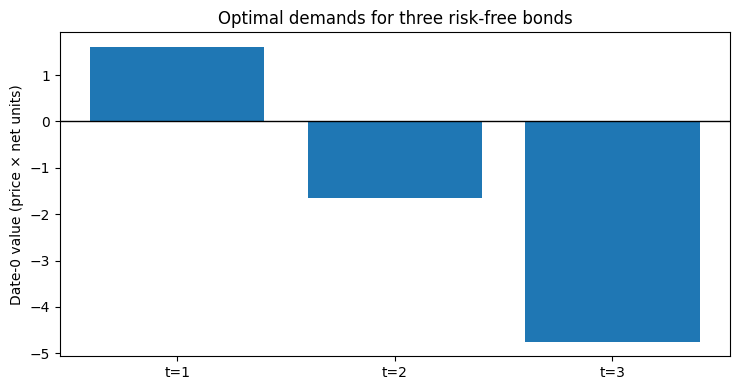

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
maturities = [1, 2, 3]
bond_values = [bond_prices[t] * bond_demand[t] for t in maturities]
ax.bar([f't={t}' for t in maturities], bond_values)
ax.axhline(0, linewidth=1, color='black')
ax.set_ylabel('Date-0 value (price × net units)')
ax.set_title('Optimal demands for three risk-free bonds')
plt.tight_layout()
plt.show()


## 11. Welfare gains relative to no assets

Use the no-assets economy as the benchmark. Let $U_A$ denote its expected lifetime utility, $U_B$ utility with three bonds, and $U_C$ utility with complete markets. We calculate the **percentage change in the numerical expected-utility index**:

$$\%\Delta U_j=100\frac{U_j-U_A}{|U_A|},\qquad j\in\{B,C\}.$$

The absolute value in the denominator makes the reported gain positive when baseline utility is negative. **Important:** A percentage change in utility is *not* an invariant welfare measure: adding a constant to felicity changes these percentages without changing preferences or optimal choices. If $U_A=0$, the percentage is undefined. We therefore also report a more economically meaningful **consumption-equivalent welfare gain**: the uniform percentage increase in consumption at every node of the no-assets allocation that would make the household indifferent to the alternative market structure. This measure is invariant to positive affine transformations of felicity.

Market structure         Expected utility    % change in U    CE gain (%)
---------------------------------------------------------------------------
No assets                        3.447511           0.0000         0.0000
Three bonds                      3.466848           0.5609         7.9569
Complete markets                 3.488035           1.1755        18.2674


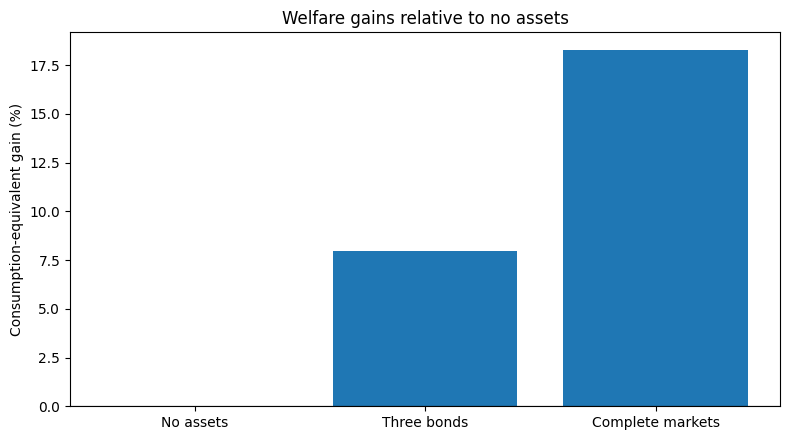

In [13]:
# Welfare comparison: baseline = no assets
U_A = expected_utility(consumption_no_assets)
U_B = expected_utility(consumption_bonds)
U_C = expected_utility(consumption)

# Invert lifetime utility along a proportional scaling of autarky consumption.
from scipy.optimize import brentq

def consumption_equivalent(target_utility):
    if abs(target_utility - U_A) < 1e-12:
        return 0.0
    def gain_at_scale(scale):
        scaled = {h: scale * c for h, c in consumption_no_assets.items()}
        return expected_utility(scaled) - target_utility
    upper = 2.0
    while gain_at_scale(upper) < 0:
        upper *= 2.0
        if upper > 1e8:
            raise ValueError('Could not bracket consumption-equivalent gain.')
    return 100 * (brentq(gain_at_scale, 1.0, upper) - 1.0)

print(f"{'Market structure':<22} {'Expected utility':>18} {'% change in U':>16} {'CE gain (%)':>14}")
print('-' * 75)
for name, U in [('No assets', U_A), ('Three bonds', U_B), ('Complete markets', U_C)]:
    utility_pct = 100 * (U - U_A) / abs(U_A) if abs(U_A) > 1e-12 else float('nan')
    ce_gain = consumption_equivalent(U)
    print(f'{name:<22} {U:>18.6f} {utility_pct:>16.4f} {ce_gain:>14.4f}')

# Graph of economically interpretable welfare improvements
names = ['No assets', 'Three bonds', 'Complete markets']
gains = [consumption_equivalent(U) for U in (U_A, U_B, U_C)]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(names, gains)
ax.set_ylabel('Consumption-equivalent gain (%)')
ax.set_title('Welfare gains relative to no assets')
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## 12. Design your own financial market

Each security is described by its **payoff at each future history**. Omitted histories have zero payoff. For example, `{'HL': 1}` pays one unit at date 2 following history HL, and nothing elsewhere.

The payoff matrix $A$ has 14 rows (future nodes) and one column per security. For portfolio $a$ and security-price vector $q=A^\top q^{AD}$, consumption is

$$c_0=e_0-q^\top a,\qquad c_{future}=e_{future}+Aa.$$

The solver maximizes discounted expected CRRA felicity subject to positive consumption at all nodes. The market is **complete** when $\operatorname{rank}(A)=14$. The number of listed securities alone does not establish completeness. To keep portfolio holdings uniquely determined, this implementation asks you to remove linearly dependent (redundant) securities.

**Important:** All these securities are bought or sold **at date 0 only**; this is not a model of dynamic trading after income is observed.

In [14]:
# EDIT THIS CELL to create a market with a few traded securities.
# Every unspecified future-node payoff is zero.
securities = {
    'Bond 1': {'H': 1, 'L': 1},
    'Bond 2': {h: 1 for h in nodes_by_date[2]},
    'Arrow HL': {'HL': 1},
}

custom_solution = solve_securities(securities)
custom_consumption = custom_solution['consumption']
print(f"Securities: {len(custom_solution['names'])}; payoff rank: {custom_solution['rank']} / 14")
print(f"{'Security':<20} {'Price':>12} {'Holding':>14}")
for name, price, holding in zip(custom_solution['names'], custom_solution['prices'], custom_solution['holdings']):
    print(f'{name:<20} {price:>12.6f} {holding:>14.6f}')
print(f"Expected utility: {custom_solution['utility']:.8f}")
print(f"Utility gain over no assets: {100*(custom_solution['utility']-U_A)/abs(U_A):.4f}%")
print(f"Consumption-equivalent gain: {consumption_equivalent(custom_solution['utility']):.4f}%")

# Check both benchmark cases with exactly the same general solver.
empty_solution = solve_securities({})
all_arrow_securities = {f'Arrow {h}': {h: 1.0} for h in future_histories}
complete_solution = solve_securities(all_arrow_securities)
assert abs(empty_solution['utility'] - U_A) < 1e-10
assert abs(complete_solution['utility'] - U_C) < 1e-6
assert np.max(np.abs(np.array([complete_solution['consumption'][h] - consumption[h] for h in all_histories]))) < 1e-3
print('Benchmark checks passed: no assets and complete markets.')

Securities: 3; payoff rank: 3 / 14
Security                    Price        Holding
Bond 1                   0.961538       0.056794
Bond 2                   0.924556      -2.832346
Arrow HL                 0.231139      -2.242305
Expected utility: 3.45734207
Utility gain over no assets: 0.2852%
Consumption-equivalent gain: 3.8931%
Benchmark checks passed: no assets and complete markets.


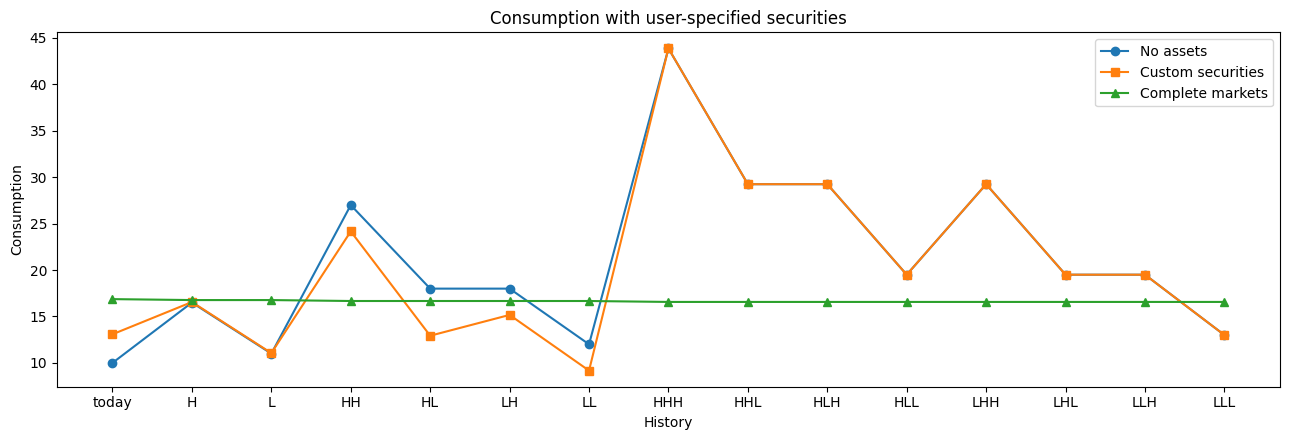

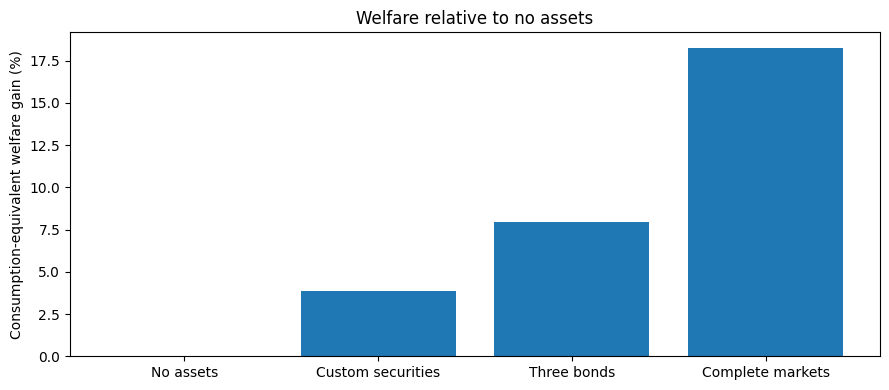

In [15]:
# Compare custom market consumption with autarky and complete markets.
fig, ax = plt.subplots(figsize=(13, 4.5))
xx = np.arange(len(all_histories))
ax.plot(xx, [consumption_no_assets[h] for h in all_histories], 'o-', label='No assets')
ax.plot(xx, [custom_consumption[h] for h in all_histories], 's-', label='Custom securities')
ax.plot(xx, [consumption[h] for h in all_histories], '^-', label='Complete markets')
ax.set_xticks(xx, labels)
ax.set_xlabel('History')
ax.set_ylabel('Consumption')
ax.set_title('Consumption with user-specified securities')
ax.legend()
plt.tight_layout()
plt.show()

names = ['No assets', 'Custom securities', 'Three bonds', 'Complete markets']
values = [0, consumption_equivalent(custom_solution['utility']),
          consumption_equivalent(U_B), consumption_equivalent(U_C)]
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(names, values)
ax.set_ylabel('Consumption-equivalent welfare gain (%)')
ax.set_title('Welfare relative to no assets')
plt.tight_layout()
plt.show()